# Introduction to Data Science Project: Housing Price data Analysis

### Yanxi Huang

### Project Overview
#### The project uses a housing price dataset to perform: missing value detection and imputation, outlier detection and treatment, correlation analysis, feature standardization, discretization, and identification of the most correlated features.

### 1. Missing Value Detection and Imputation
#### 1.1 Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer

#### 1.2 Load the Dataset

In [2]:
df=pd.read_csv("house_train.csv")

#### 1.3 Detect Missing Values

In [3]:
total=df.isnull().sum().sort_values(ascending=False)
percent=(df.isnull().sum()/
        df.isnull().count()).sort_values(ascending=False)
missing_data=pd.concat([total,percent],axis=1,keys=['Total','Percent'])
missing_data

,Total,Percent
crime_rate,4,0.0020
green_rate,3,0.0015
id,0,0.0000
built_date,0,0.0000
distirct,0,0.0000
area,0,0.0000
floor,0,0.0000
traffic,0,0.0000
oriented,0,0.0000
shockproof,0,0.0000


#### 1.4 Handle Missing Values
##### The table shows that "crime_rate" contains the most missing values, but the missing rate is only 0.2%. Therefore, no tuple should be discarded. 
##### We instead impute missing values using the column mean for numeric features and the most frequent value for categorical features.

In [4]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
non_numeric_cols = df.select_dtypes(exclude=['int64', 'float64']).columns

imp_numeric = SimpleImputer(strategy='mean')
df_numeric = pd.DataFrame(
    imp_numeric.fit_transform(df[numeric_cols]),
    columns=numeric_cols
)

if not non_numeric_cols.empty:
    imp_non_numeric = SimpleImputer(strategy='most_frequent')
    df_non_numeric = pd.DataFrame(
        imp_non_numeric.fit_transform(df[non_numeric_cols]),
        columns=non_numeric_cols
    )
    
    df_cleaned = pd.concat([df_numeric, df_non_numeric], axis=1)
else:
    df_cleaned = df_numeric

output_path = r"house_train_cleaned.csv"
df_cleaned.to_csv(output_path, index=False, encoding='utf-8')

print(f"Data saved to:{output_path}")
print("Total rows:", len(df_cleaned))

Data saved to:house_train_cleaned.csv
Total rows: 2000


### 2. Outlier Detection and Treatment
#### 2.1 Import Required Libraries

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

#### 2.2 Automatic Outlier Detection and Treatment
##### The "id" column is excluded as an identifier. The "oriented" column is binary and is not checked for outliers.
##### For each remaining numeric column, we first test normality. If the data are approximately normal, we use the 3σ rule; otherwise, we use the IQR rule.
##### Detected outliers are replaced with the mean.
##### Finally, we visualize the original and processed distributions and save an outlier report.

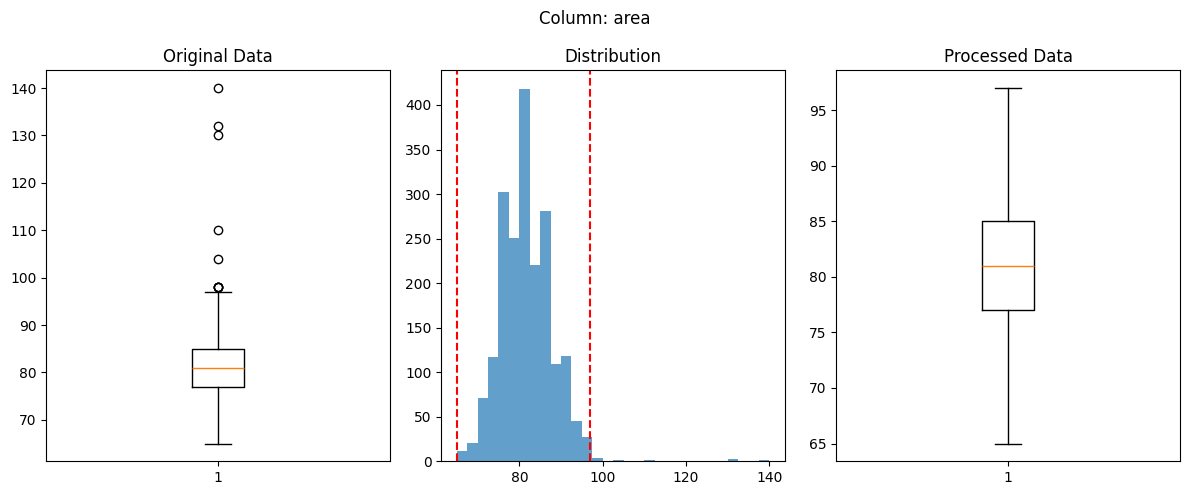

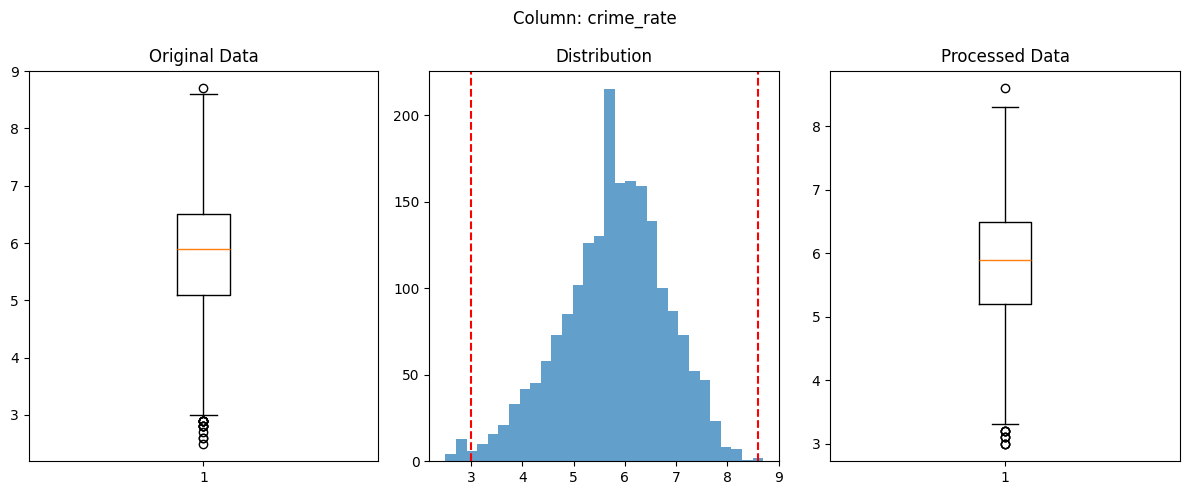

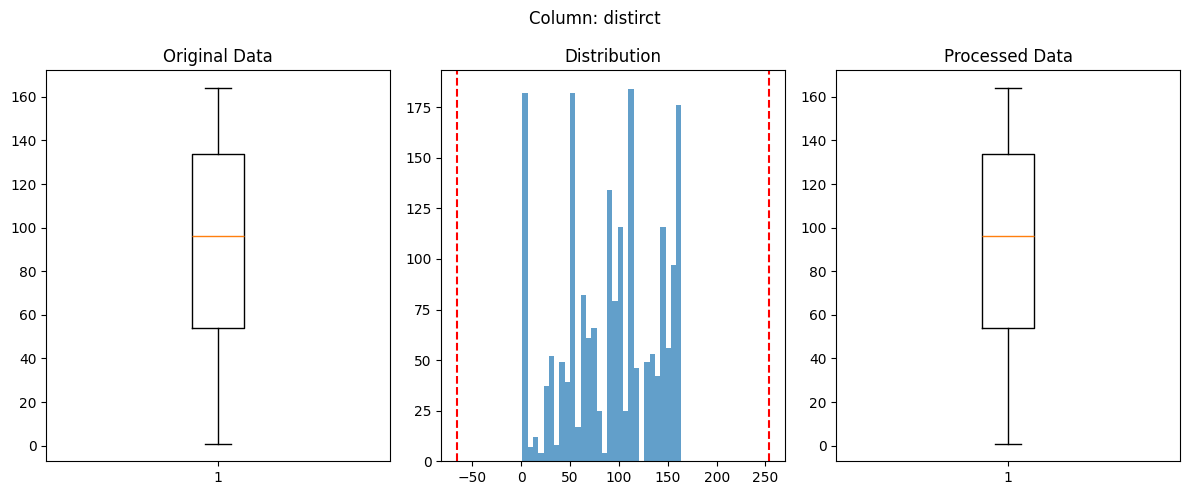

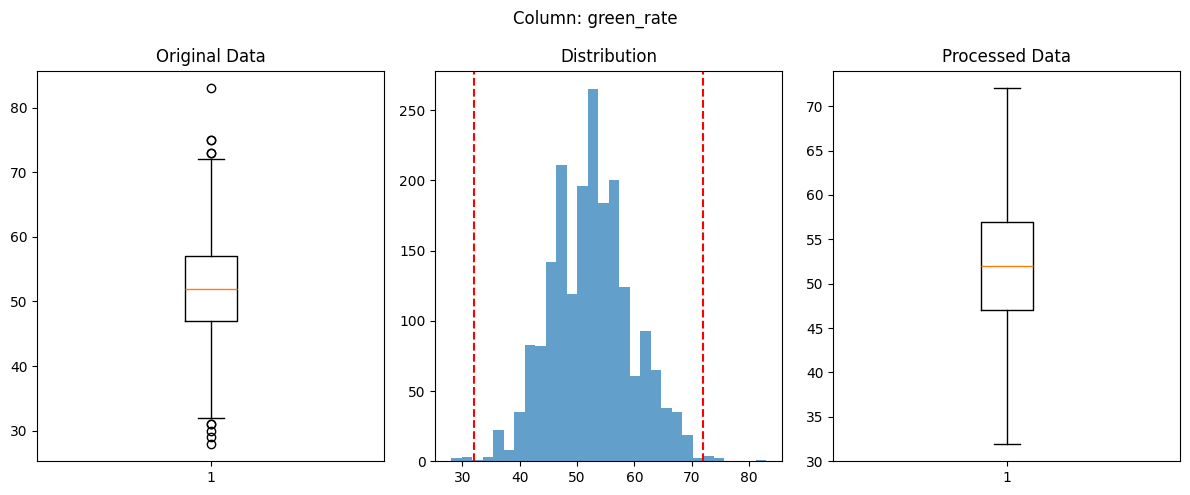

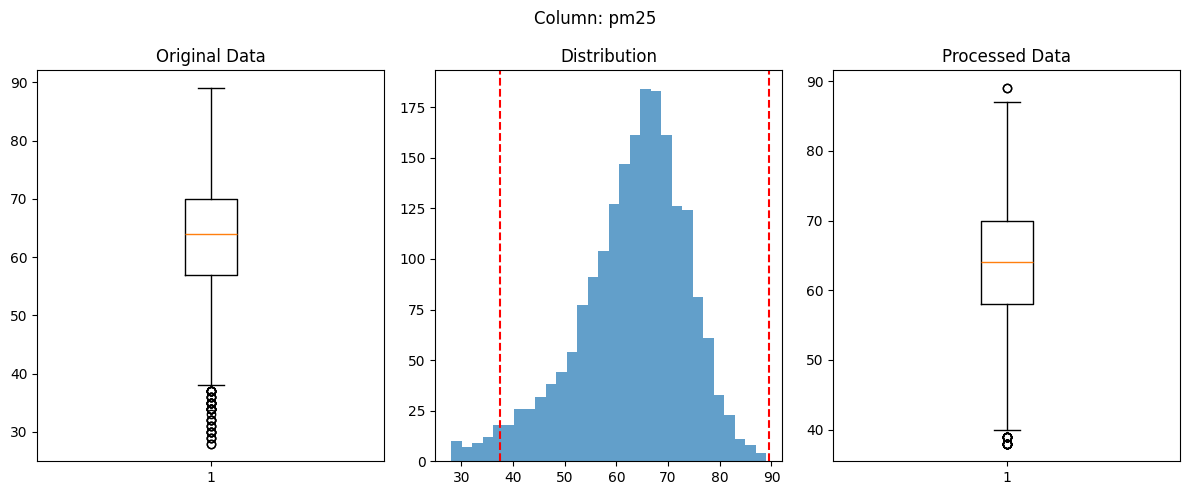

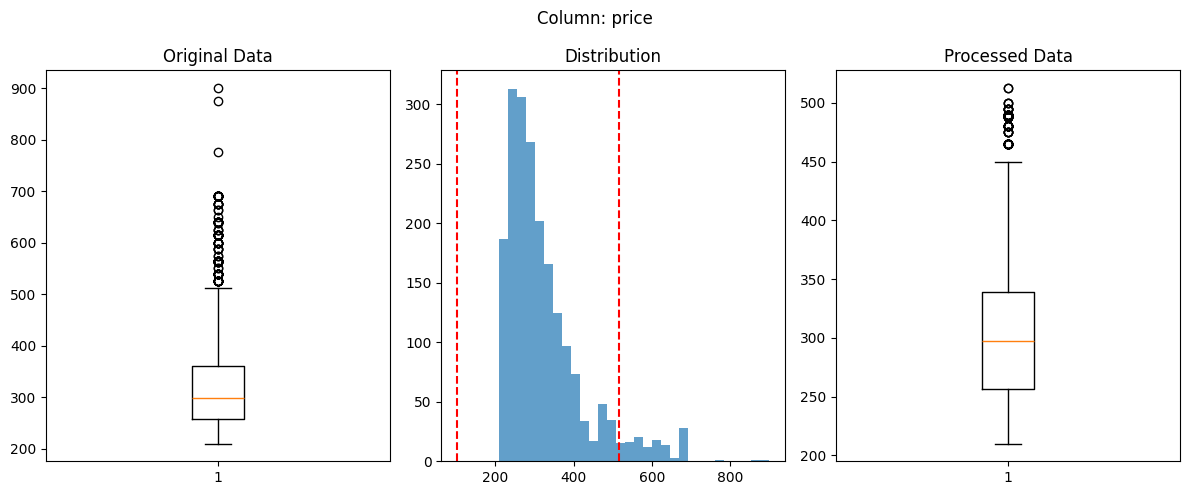

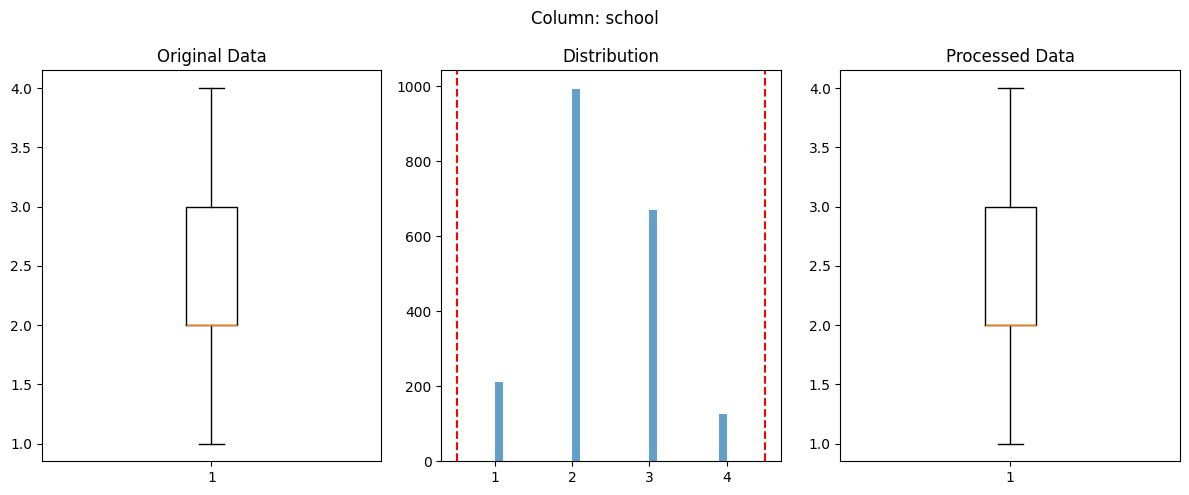

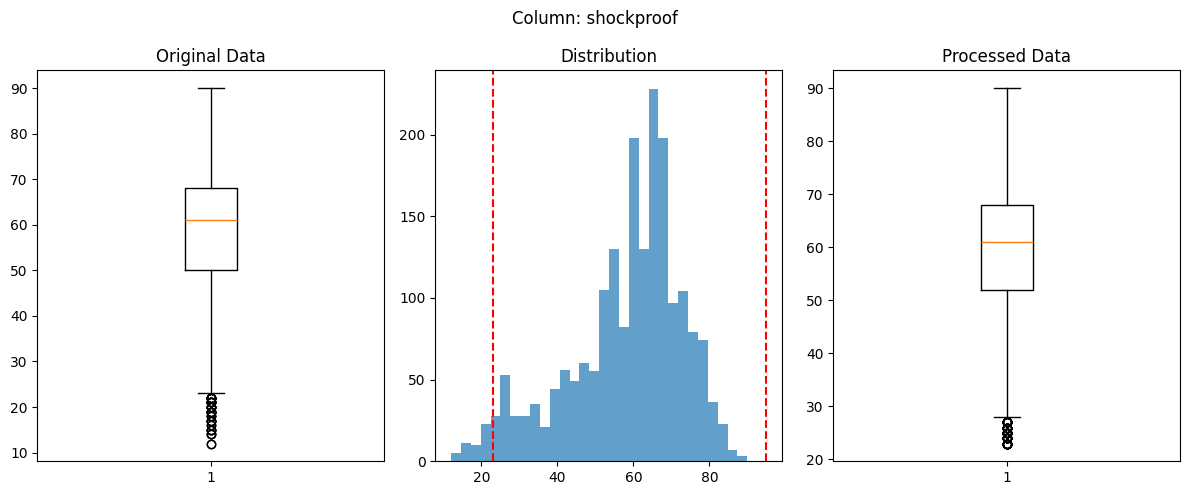

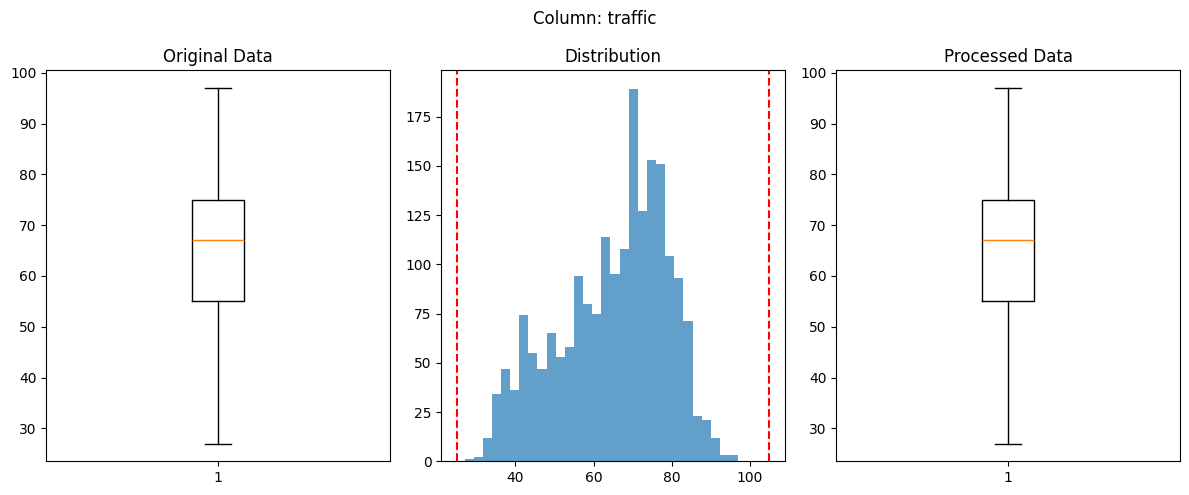

Processing complete. Original rows: 2000, processed rows: 2000
Outlier ratio by column:
           outliers outlier_ratio
price           127        0.0635
shockproof       49        0.0245
pm25             46         0.023
crime_rate       18         0.009
green_rate       10         0.005
area              9        0.0045
distirct          0           0.0
school            0           0.0
traffic           0           0.0


In [6]:
def process_all_columns(
    df,
    handle_method='clip',
    exclude_columns=['id','oriented'],
    show_plot=False,
    iqr_multiplier=1.5,
    sigma_multiplier=3,
    report_path='outlier_report.csv'
):
    """
    异常值处理主函数（优化版）

    参数：
    df: 原始数据框
    handle_method: 异常值处理方式，可选 ['clip', 'median', 'mean', 'remove', 'mark']
    exclude_columns: 需要排除的列
    show_plot: 是否显示处理前后对比图
    iqr_multiplier: IQR方法的阈值倍数
    sigma_multiplier: 3σ方法的阈值倍数
    report_path: 报告文件保存路径

    返回：
    cleaned_df: 处理后的数据框
    report: 处理报告字典
    """
    # 1. 准备数值型列
    numeric_columns = df.select_dtypes(include=['number']).columns.difference(exclude_columns)
    
    cleaned_df = df.copy()
    report = {}
    outlier_mask_combined = pd.Series(False, index=df.index)  # 使用Pandas Series优化

    for col in numeric_columns:
        col_data = df[col].dropna()  # 移除缺失值
        n_total = len(col_data)
        
        # 跳过数据不足的列
        if n_total < 3:
            report[col] = {
                'status': 'skipped',
                'reason': '有效数据不足（<3）',
                'total_values': n_total
            }
            continue

        # 2. 正态性检验
        try:
            # 使用D'Agostino-Pearson检验（更适合大数据）
            k2, p = stats.normaltest(col_data)
            use_3sigma = (p > 0.05)
        except:
            use_3sigma = False

        # 3. 计算边界
        if use_3sigma:
            mu, sigma = col_data.mean(), col_data.std()
            lower = mu - sigma_multiplier * sigma
            upper = mu + sigma_multiplier * sigma
            method_name = f'{sigma_multiplier}σ'
        else:
            q1, q3 = col_data.quantile([0.25, 0.75])
            iqr = q3 - q1
            lower = q1 - iqr_multiplier * iqr
            upper = q3 + iqr_multiplier * iqr
            method_name = f'IQR ({iqr_multiplier}x)'

        # 4. 检测异常值
        outlier_mask = (df[col] < lower) | (df[col] > upper)
        n_outliers = outlier_mask.sum()
        outlier_ratio = n_outliers / n_total

        # 5. 处理逻辑
        replacement = None
        if handle_method in ['median', 'mean']:
            non_outliers = col_data[~outlier_mask[col_data.index]]
            
            if len(non_outliers) == 0:
                report[col] = {
                    'status': 'failed',
                    'reason': 'All the values are outliers',
                    'total_values': n_total
                }
                continue
                
            replacement = non_outliers.median() if handle_method == 'median' else non_outliers.mean()
            cleaned_df[col] = df[col].mask(outlier_mask, replacement)
        elif handle_method == 'clip':
            cleaned_df[col] = np.clip(df[col], lower, upper)
        elif handle_method == 'remove':
            outlier_mask_combined |= outlier_mask
        elif handle_method == 'mark':
            cleaned_df[f"{col}_is_outlier"] = outlier_mask.astype(int)

        # 6. 生成报告
        report[col] = {
            'method': method_name,
            'outliers': n_outliers,
            'outlier_ratio': round(outlier_ratio, 4),
            'bounds': [round(lower, 2), round(upper, 2)],
            'pre_mean': round(col_data.mean(), 2),
            'post_mean': round(cleaned_df[col].mean(), 2),
            'pre_std': round(col_data.std(), 2),
            'post_std': round(cleaned_df[col].std(), 2),
            'replacement': replacement if replacement else None
        }

        # 7. 可视化
        if show_plot:
            plt.figure(figsize=(12, 5))
            plt.suptitle(f'Column: {col}')
            
            plt.subplot(131)
            plt.boxplot(col_data)
            plt.title('Original Data')
            
            plt.subplot(132)
            plt.hist(col_data, bins=30, alpha=0.7, label='Original')
            plt.axvline(lower, color='r', linestyle='--')
            plt.axvline(upper, color='r', linestyle='--')
            plt.title('Distribution')
            
            plt.subplot(133)
            plt.boxplot(cleaned_df[col].dropna())
            plt.title('Processed Data')
            
            plt.tight_layout()
            plt.show()

    # 8. 处理行删除
    if handle_method == 'remove':
        cleaned_df = cleaned_df[~outlier_mask_combined]

    # 9. 保存结构化报告
    report_df = pd.DataFrame(report).T
    report_df.to_csv(report_path, encoding='utf-8-sig')  # 支持中文

    return cleaned_df, report

# ----------------- 执行示例 -----------------
if __name__ == "__main__":
    # 读取数据
    file_path = r"house_train_cleaned.csv"
    df = pd.read_csv(file_path)

    # 执行处理
    cleaned_df, report = process_all_columns(
        df,
        handle_method='mean',  # 使用均值替换
        show_plot=True,         # 显示可视化
        sigma_multiplier=3,     # 可调整参数
        iqr_multiplier=1.5
    )

    # 保存结果
    output_path = r"house_train_final.csv"
    cleaned_df.to_csv(output_path, index=False, encoding='utf-8-sig')

    # 打印简要报告
    print(f"Processing complete. Original rows: {len(df)}, processed rows: {len(cleaned_df)}")
    print("Outlier ratio by column:")
    report_df = pd.DataFrame(report).T
    print(report_df[['outliers', 'outlier_ratio']].sort_values('outlier_ratio', ascending=False))

### 3. Correlation Analysis between Features
#### 3.1 Import Required Libraries

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as matplot
import seaborn as sns
get_ipython().run_line_magic('matplotlib', 'inline')

#### 3.2 Load the Processed Data and Check for Missing Values

In [8]:
df = pd.read_csv(r"house_train_final.csv", index_col=None)
print(df.isnull().any())

id            False
distirct      False
green_rate    False
area          False
oriented      False
traffic       False
shockproof    False
school        False
crime_rate    False
pm25          False
price         False
built_date    False
floor         False
dtype: bool


#### 3.3 Further Data Processing
##### Inspect Data Types

In [9]:
df.head()

,id,distirct,green_rate,area,oriented,traffic,shockproof,school,crime_rate,pm25,price,built_date,floor
0,1.0,164.0,45.0,90.0,0.0,74.0,70.0,2.0,6.5,72.0,380.00,2003/1/4,Medium
1,2.0,111.0,51.0,72.0,0.0,61.0,65.0,3.0,5.8,55.0,245.00,2000/6/18,Low
2,3.0,28.0,58.0,92.0,1.0,94.0,39.0,2.0,7.0,87.0,212.50,1993/9/27,Medium
3,4.0,90.0,45.0,83.0,1.0,81.0,39.0,3.0,7.4,74.0,480.00,1993/6/6,Medium
4,5.0,63.0,62.0,77.0,1.0,71.0,83.0,1.0,6.5,71.0,293.75,1997/7/15,Medium


##### Rename Selected Columns for Readability.
##### And move the variable "price" that needs to be analyzed to the front of the table.

In [10]:
import os
df=pd.read_csv(r"house_train_final.csv")

df=df.rename(columns={
    'green_rate':'green',
    'crime_rate':'crime',
    'built_date':'built'
})

front=df['price']
df=df.drop(labels=['price'], axis=1)
df.insert(0, 'price', front)

output_folder = '.'
output_path = os.path.join(output_folder, 'processed1_house_data.csv')
df.to_csv(output_path, index=False, encoding='utf-8')
print("Intermediate file exported!")
df.head()

Intermediate file exported!


,price,id,distirct,green,area,oriented,traffic,shockproof,school,crime,pm25,built,floor
0,380.00,1.0,164.0,45.0,90.0,0.0,74.0,70.0,2.0,6.5,72.0,2003/1/4,Medium
1,245.00,2.0,111.0,51.0,72.0,0.0,61.0,65.0,3.0,5.8,55.0,2000/6/18,Low
2,212.50,3.0,28.0,58.0,92.0,1.0,94.0,39.0,2.0,7.0,87.0,1993/9/27,Medium
3,480.00,4.0,90.0,45.0,83.0,1.0,81.0,39.0,3.0,7.4,74.0,1993/6/6,Medium
4,293.75,5.0,63.0,62.0,77.0,1.0,71.0,83.0,1.0,6.5,71.0,1997/7/15,Medium


##### Check Data Types

In [11]:
df.dtypes

price         float64
id            float64
distirct      float64
green         float64
area          float64
oriented      float64
traffic       float64
shockproof    float64
school        float64
crime         float64
pm25          float64
built          object
floor          object
dtype: object

##### Process Non-Numeric Columns
##### Convert "built_date" to datetime and extract the year as "built_year". Map the ordinal "floor" levels to 1, 2, and 3. Drop the "id" column because it is only an identifier.

In [12]:
df = pd.read_csv(r"processed1_house_data.csv")

# 处理属性“id”
if 'id' in df.columns:
    df = df.drop('id', axis=1)
    
# 处理属性“built”
df['built'] = pd.to_datetime(df['built'])
df['年份'] = df['built'].dt.year
df = df.drop('built', axis=1)

# 处理属性“floor”
floor_mapping = {
    'Low': 1,
    'Medium': 2,
    'High': 3
}
df['floor'] = df['floor'].map(floor_mapping)

output_folder = '.'
output_path = os.path.join(output_folder, 'processed2_house_data.csv')
df.to_csv(output_path, index=False, encoding='utf-8')
print("Data exported to processed2_house_data.csv！")

Data exported to processed2_house_data.csv！


#### 3.4 Correlation Analysis
##### All features are now numeric.
##### Next, draw the correlation matrix and the correlation coefficient heatmap.

In [13]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap, rgb_to_hsv
df = pd.read_csv(r"processed2_house_data.csv")

# -------------------------- 计算相关系数矩阵 --------------------------
corr = df.select_dtypes(include='number').corr().round(2) # 保留两位小数

# 显示带颜色梯度的表格
corr.style.background_gradient(
    cmap='coolwarm',        # 颜色映射
    axis=None,              # 全局范围
    vmin=-1, vmax=1         # 相关系数范围
).set_properties(**{
    'font-size': '10pt',    # 字体大小
    'text-align': 'center', # 居中对齐
    'border': '1px solid black'  # 边框
}).set_caption("correlation matrix")  # 标题

,price,distirct,green,area,oriented,traffic,shockproof,school,crime,pm25,floor,年份
price,1.000000,-0.040000,0.020000,0.410000,-0.050000,0.280000,0.230000,0.170000,0.330000,0.320000,0.070000,-0.160000
distirct,-0.040000,1.000000,0.070000,-0.040000,-0.010000,-0.020000,-0.070000,-0.040000,-0.060000,-0.020000,-0.010000,0.060000
green,0.020000,0.070000,1.000000,-0.020000,0.050000,0.010000,-0.210000,-0.400000,-0.110000,-0.180000,-0.180000,-0.180000
area,0.410000,-0.040000,-0.020000,1.000000,0.010000,0.300000,0.280000,0.200000,0.400000,0.470000,0.090000,0.260000
oriented,-0.050000,-0.010000,0.050000,0.010000,1.000000,0.030000,-0.060000,-0.090000,-0.060000,-0.010000,-0.010000,0.020000
traffic,0.280000,-0.020000,0.010000,0.300000,0.030000,1.000000,0.130000,0.270000,0.610000,0.720000,0.310000,-0.240000
shockproof,0.230000,-0.070000,-0.210000,0.280000,-0.060000,0.130000,1.000000,0.400000,0.360000,0.220000,0.150000,-0.100000
school,0.170000,-0.040000,-0.400000,0.200000,-0.090000,0.270000,0.400000,1.000000,0.220000,0.360000,0.300000,0.000000
crime,0.330000,-0.060000,-0.110000,0.400000,-0.060000,0.610000,0.360000,0.220000,1.000000,0.740000,0.200000,-0.310000
pm25,0.320000,-0.020000,-0.180000,0.470000,-0.010000,0.720000,0.220000,0.360000,0.740000,1.000000,0.310000,-0.170000


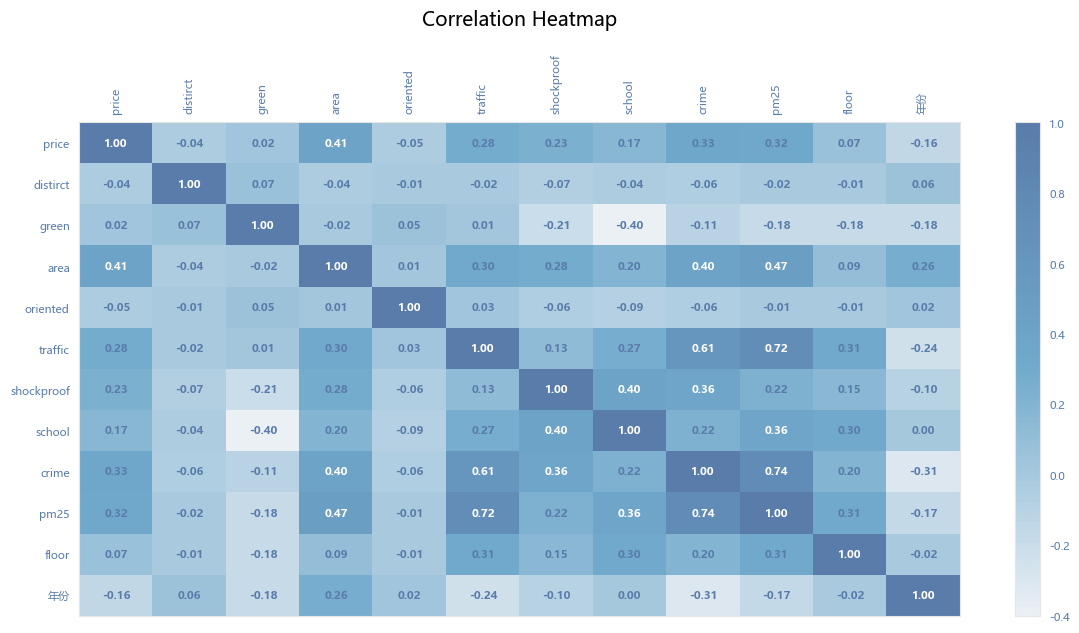

In [14]:
# -------------------------- 绘制热力图 --------------------------
plt.rcParams["font.sans-serif"]=["Microsoft YaHei"] #显示中文
plt.rcParams["axes.unicode_minus"]=False# 显示负号
plt.rcParams["axes.edgecolor"]="#e5e5e5"# 去边框
plt.rcParams["axes.labelweight"]="bold" #轴标签文本字重
plt.rcParams["xtick.color"]="#ffffff" #x轴刻度颜色
plt.rcParams["ytick.color"]="#ffffff"#y轴刻度颜色
plt.rcParams["xtick.labelcolor"]="#597cab"#x轴标签颜色
plt.rcParams["ytick.labelcolor"]="#597cab" #y轴标签颜色
plt.rcParams["xtick.labelsize"]=8 #x轴标签字号
plt.rcParams["ytick.labelsize"]=8#y轴标签字号
#生成示例数据
fig,ax=plt.subplots(figsize=(12,6))
#自定义颜色映射
colors=["#ebf0f5","#71aacc","#597cab"]
n_bins=100 #使用多少个颜色分段
cmap_name ="my_custom_cmap"
#创建颜色映射
cmap= LinearSegmentedColormap.from_list(
    cmap_name,colors,N=n_bins)
cax=ax.matshow(corr,cmap=cmap,aspect="auto")
#在热力图上添加颜色条
fig.colorbar(cax)
#设置轴标签
column_names = corr.columns.tolist()
ax.set_xticks(np.arange(len(column_names)))
ax.set_yticks(np.arange(len(column_names)))
ax.set_xticklabels(column_names, rotation=90)  # x轴标签旋转90度
ax.set_yticklabels(column_names)               # y轴标签水平显示


#在每个单元格上显示数据值
for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        value =corr.iloc[i,j]
        color = cmap(value)
        hsv=rgb_to_hsv(color[:3])#计算背景颜色的亮度
        brightness=hsv[2]#取亮度值
        text_color ="#597cab" if brightness >0.85 else "white"
        ax.text(
            j,i,f"{value:.2f}",ha="center",va="center",
            color=text_color,size=8,weight="bold"
        )

plt.tight_layout()  # 自动调整布局
plt.title("Correlation Heatmap", fontsize=14, pad=20)
plt.show()

##### The heatmap shows positive correlations between traffic and both PM2.5 and crime rate. 
##### Area is positively correlated with PM2.5, price, and crime rate. 
##### Price is positively correlated with area, crime rate, PM2.5, and traffic.
##### In terms of negative correlations, school is strongly negatively correlated with green space, and built year is negatively correlated with crime rate.

### 4. Standardization of the Price Feature
#### We apply Z-score standardization so that price has mean 0 and standard deviation 1.

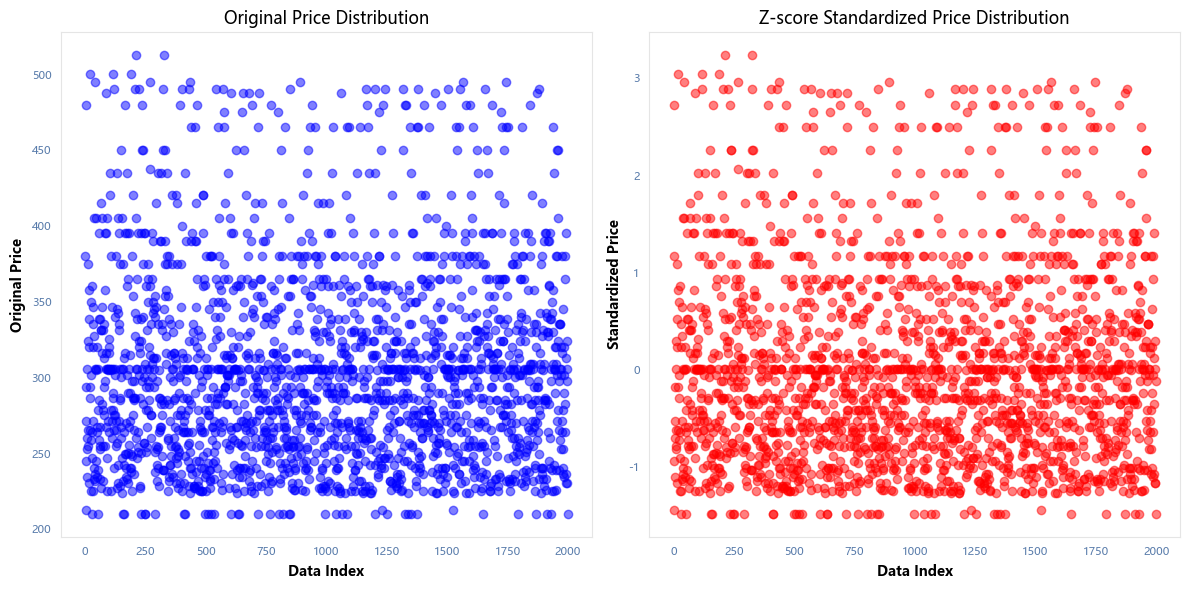

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

data = pd.read_csv(r"processed2_house_data.csv")
scaler = StandardScaler()
data['price_zscore'] = scaler.fit_transform(data[['price']])

# 绘制标准化后数据散点图
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.scatter(range(len(data)), data['price'], color='blue', alpha=0.5)
plt.title("Original Price Distribution")
plt.xlabel("Data Index")
plt.ylabel("Original Price")

plt.subplot(1, 2, 2)
plt.scatter(range(len(data)), data['price_zscore'], color='red', alpha=0.5)
plt.title("Z-score Standardized Price Distribution")
plt.xlabel("Data Index")
plt.ylabel("Standardized Price")

plt.tight_layout()
plt.show()

### 5. Discretization of the Price Feature
#### We use equal-width binning to discretize price into five bins.

In [16]:
import pandas as pd

num_bins = 5  # 分箱数量
data['price_eq_width'] = pd.cut(
    data['price'],
    bins=num_bins,
    labels=[f'Bin_{i+1}' for i in range(num_bins)]
)

print(data['price_eq_width'].value_counts())

price_eq_width
Bin_2    754
Bin_1    692
Bin_3    345
Bin_4    124
Bin_5     85
Name: count, dtype: int64


### 6. Top Three Features Most Correlated with Price
#### Based on the correlation matrix in Section 3, the three features most correlated with price are area, crime rate, and PM2.5.
#### Next, we will explain these three features.

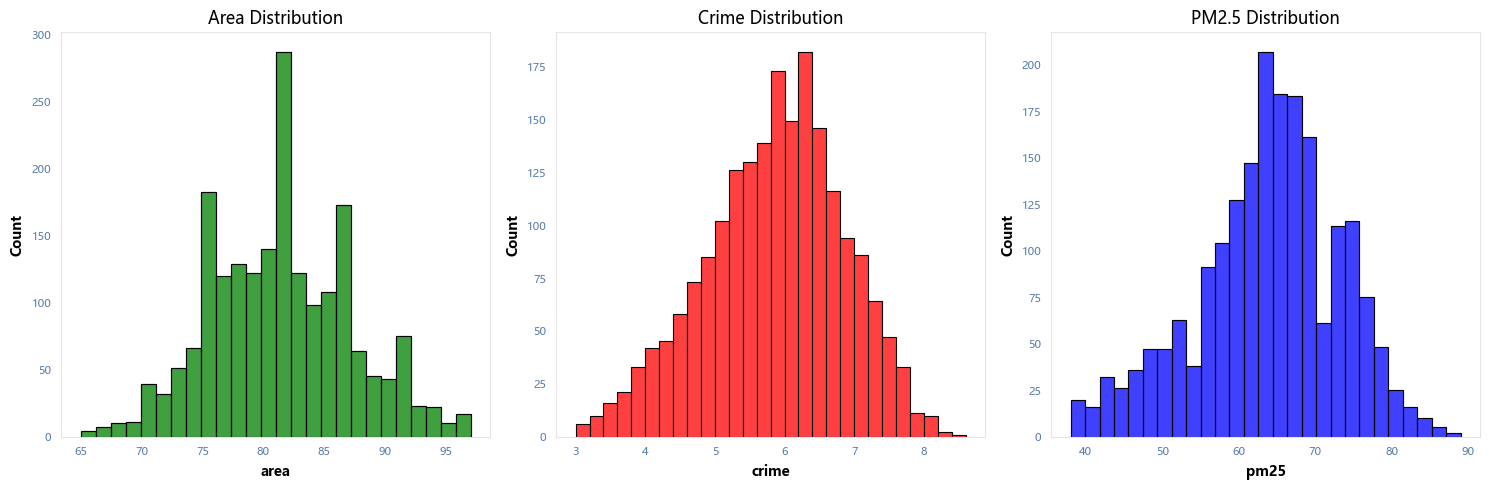

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# 导入数据
df = pd.read_csv(r"standardized_dataset.csv")

# 设置画布
plt.figure(figsize=(15, 5))

# 绘制 area 直方图
plt.subplot(1, 3, 1)
sns.histplot(df['area'], color='g', kde=False)
plt.title('Area Distribution')

# 绘制 crime 直方图
plt.subplot(1, 3, 2)
sns.histplot(df['crime'], color='r', kde=False)
plt.title('Crime Distribution')

# 绘制 pm25 直方图
plt.subplot(1, 3, 3)
sns.histplot(df['pm25'], color='b', kde=False)
plt.title('PM2.5 Distribution')

plt.tight_layout()
plt.show()

##### The three features are approximately normally distributed.
##### Area has dense values around 75, 82, and 86. 
##### Crime rate is concentrated around 6.
##### PM2.5 peaks between 64 and 68.

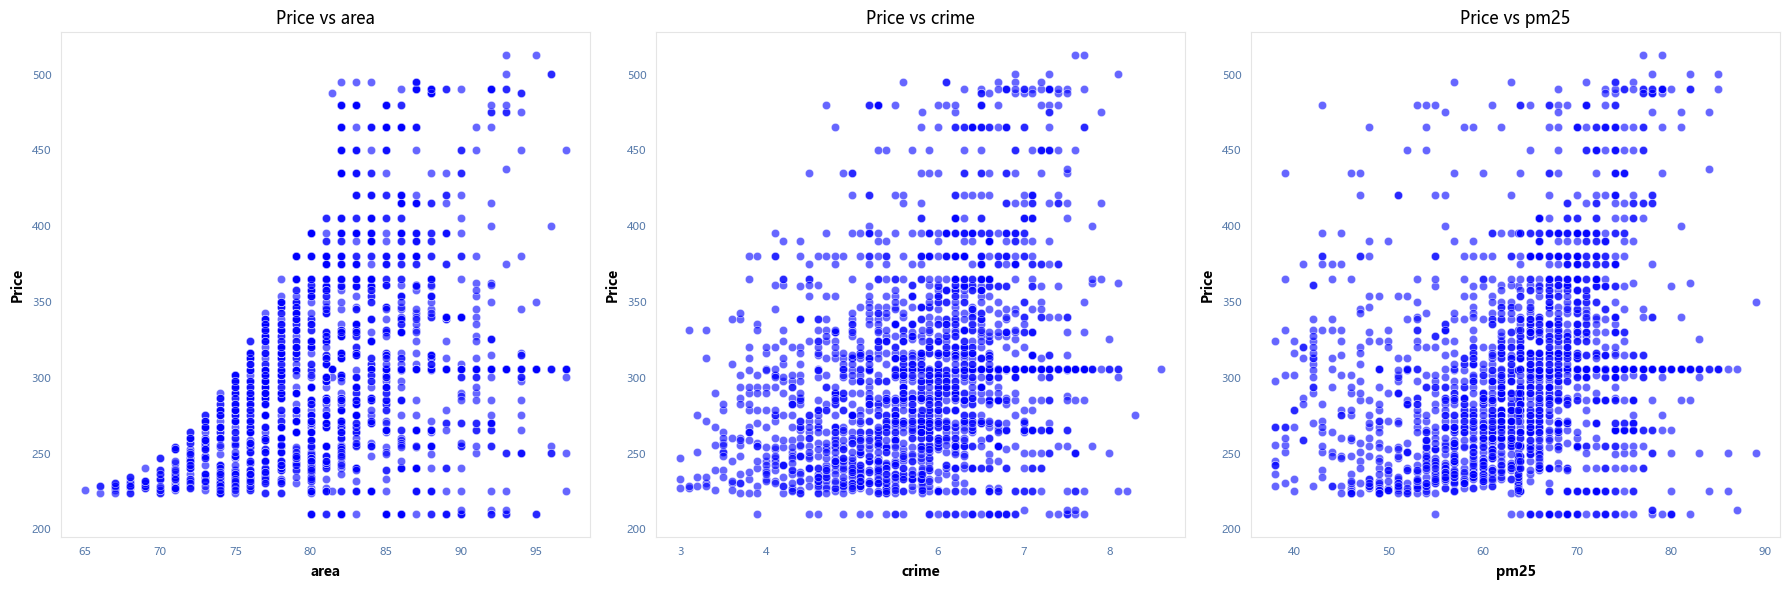

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 加载数据
data = pd.read_csv(r"standardized_dataset.csv")

# 设置画布和子图
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 特征列表
features = ['area', 'crime', 'pm25']

# 绘制散点图
for i, feature in enumerate(features):
    sns.scatterplot(
        data=data,
        x=feature,
        y='price',
        ax=axes[i],
        alpha=0.6,
        color='blue'
    )
    axes[i].set_title(f"Price vs {feature}")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Price")

plt.tight_layout()
plt.show()

##### Overall, larger area is associated with higher price, higher crime rate is associated with higher price, and higher PM2.5 is associated with higher price. 
##### However, the scatter plots show substantial dispersion, so these are directional trends rather than deterministic relationships.

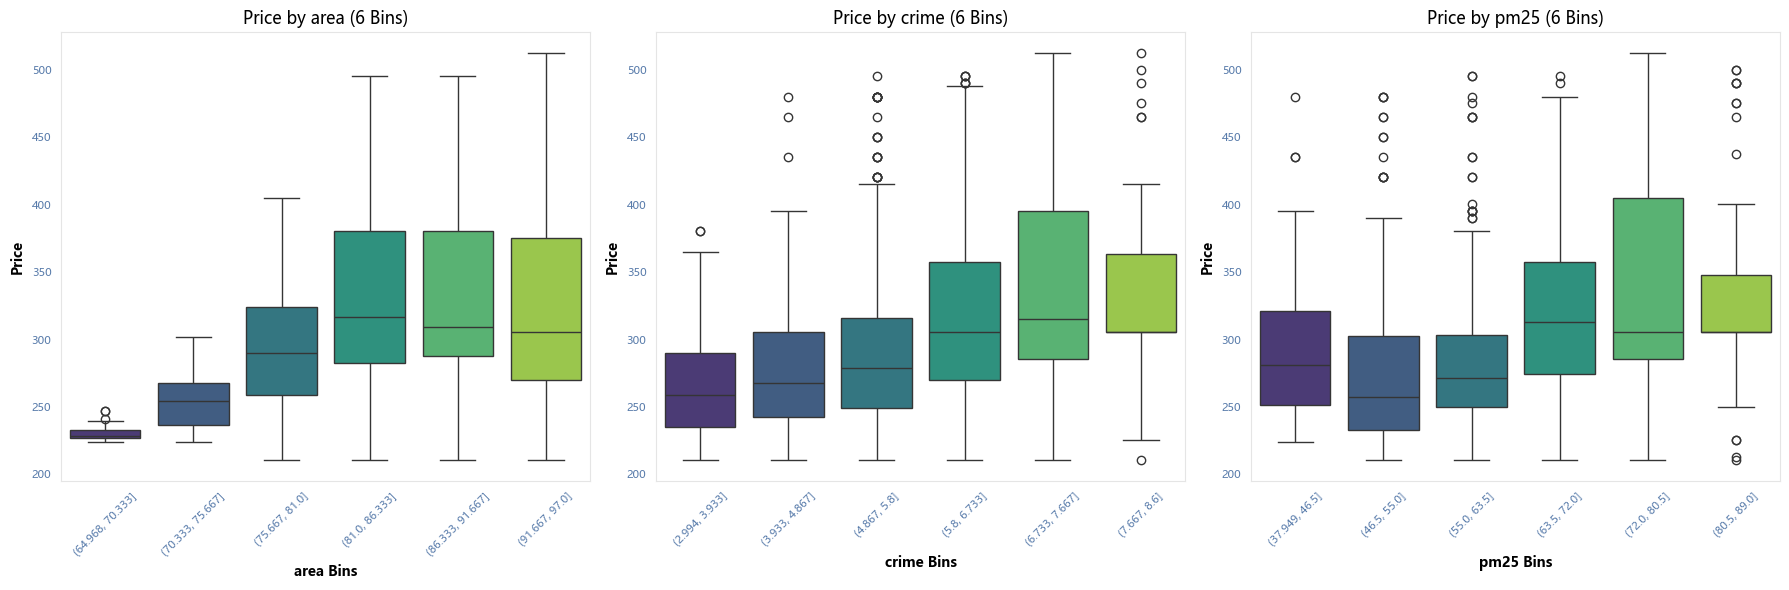

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 加载数据
data = pd.read_csv(r"standardized_dataset.csv")

# 设置画布和子图
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 定义特征列表和分箱参数
features = ['area', 'crime', 'pm25']
n_bins = 6  # 修改为6个分箱

# 循环绘制每个特征的分箱图
for i, feature in enumerate(features):
    # 分箱（等宽分箱）
    data[f'{feature}_bin'] = pd.cut(data[feature], bins=n_bins)
    
    # 绘制箱线图（兼容最新Seaborn）
    sns.boxplot(
        data=data,
        x=f'{feature}_bin',
        y='price',
        hue=f'{feature}_bin',  # 消除警告的关键修改
        palette='viridis',
        ax=axes[i],
        showfliers=True,      # 隐藏离群值
        legend=False           # 关闭图例
    )
    
    # 设置标题和标签
    axes[i].set_title(f"Price by {feature} (6 Bins)")
    axes[i].set_xlabel(f"{feature} Bins")
    axes[i].set_ylabel("Price")
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

##### From the above graph, Area - When the area is relatively large, such as within the range of 81.0 - 97.0, the upper limit of the house price is higher and the lower limit is lower. Moreover, the means of the three bins [81.0, 86.333], [86.333, 91.667], and [91.667, 97.0] are similar, indicating that in houses with these areas, the differences in house prices may not be significant.
##### In the three bins [3.933, 4.867], [4.867, 5.8], and [7.667, 8.6], there are more outliers, indicating that there might be certain deviations.
##### PM2.5 - In almost all the bins, there are certain outliers, indicating that there might be significant deviations.

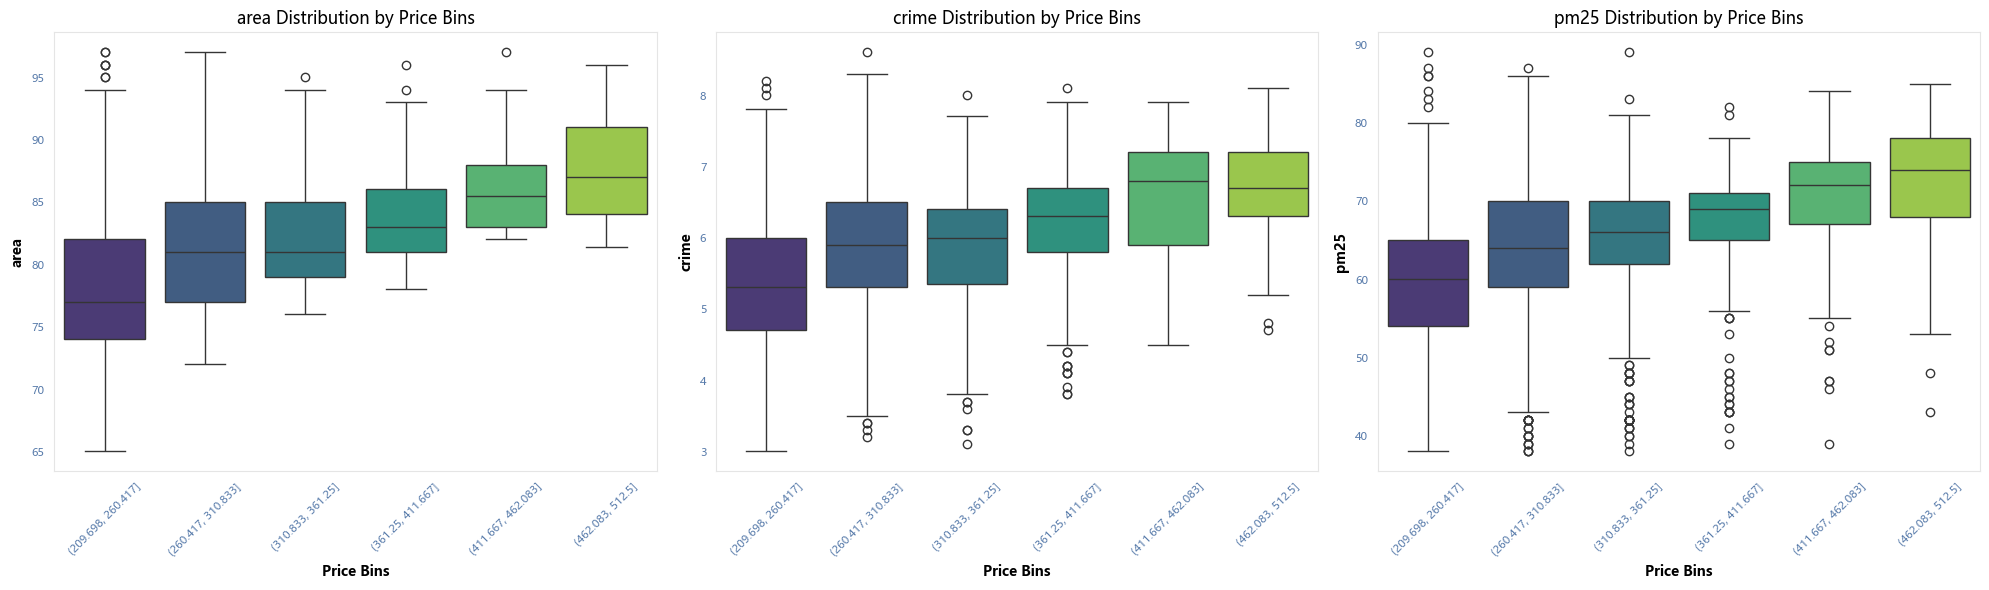

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 加载数据
data = pd.read_csv(r"standardized_dataset.csv")

# 设置画布和子图
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 定义分箱数量和特征列表
n_bins = 6  # 分6个箱
features = ['area', 'crime', 'pm25']

# 对price进行分箱（等宽分箱）
data['price_bin'] = pd.cut(data['price'], bins=n_bins)

# 循环绘制每个子图
for i, feature in enumerate(features):
    # 绘制箱线图（x=price分箱，y=特征值）
    sns.boxplot(
        data=data,
        x='price_bin',  # 横坐标为price的分箱
        y=feature,       # 纵坐标为当前特征（area/crime/pm25）
        hue='price_bin', # 解决Seaborn警告
        palette='viridis',
        ax=axes[i],
        showfliers=True,  # 显示离群值
        legend=False      # 关闭图例
    )
    
    # 设置图表标题和标签
    axes[i].set_title(f"{feature} Distribution by Price Bins")
    axes[i].set_xlabel("Price Bins")
    axes[i].set_ylabel(feature)
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

##### For area, lower-priced homes show a wider spread.
##### For crime rate, the mean is around 6 across price bins, but lower-priced bins show wider variability.
##### For PM2.5, outliers appear across most price bins, suggesting that PM2.5 may be a weaker predictor than area or crime rate.

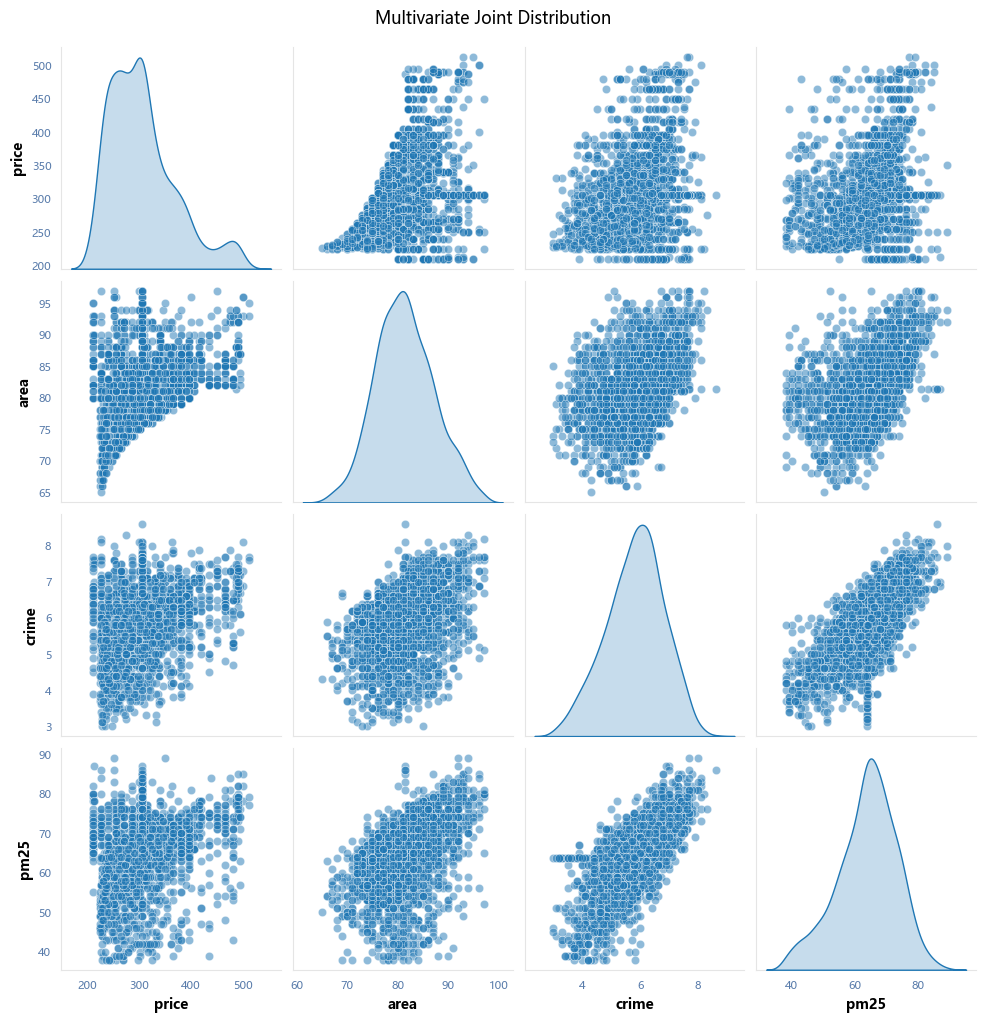

In [22]:
sns.pairplot(data[['price', 'area', 'crime', 'pm25']], 
             diag_kind='kde', 
             plot_kws={'alpha': 0.5})
plt.suptitle("Multivariate Joint Distribution", y=1.02)
plt.show()

##### The above figure presents the correlations, distribution patterns and outliers among all the variables.
##### The above picture can support the aforementioned viewpoint.